
# The files that you need to deal with are:
1.   VPTD_Dataset.csv  :: contains the ground truth for personality traits and sales  estimation
2.   smiles.csv :: contains the smiles detected in each video from the dataset.
3.   head_movements.json :: contains the info about the head movments (roll, pitch, yaw) for each frame




## Task 1: (6 marks)
* Build a classification system for the sales abilities based on the personality traits.
* You can use the idea presented in the lecture which states that good salesmen have high levels of (Openness, Conscientiousness and Extraversion) and low levels of (Agreeableness and Neuroticism) or you can build your own classification system.
* Implement the classification system on the data and visualize the results and compare it with the SE (self-estimated sales abilities by the participants)






,Id_name,Extraversion,Agreeableness,Conscientiousness,Neuroticism,Openness,SalesScore,SalesClass,SE
0,MKdgEMd_con,0.720,0.850,0.770,0.270,0.700,8.00,4,4
1,bdVZIIm_EuX,0.900,0.950,0.825,0.300,0.750,8.00,4,4
2,HaKCwkz_Krw,0.850,0.900,0.925,0.225,0.700,8.00,4,3
3,EPhoawa_cLI,0.725,0.700,0.675,0.150,0.800,8.00,4,4
4,INHfwiw_yNA,0.725,0.750,0.675,0.250,0.850,8.00,4,4
5,HmakBQy_Zuo,0.640,0.520,0.800,0.320,0.650,7.80,4,4
6,KTbiJPN_nFG,0.825,0.700,0.600,0.075,0.975,7.80,4,5
7,opJgPXE_gNj,0.700,0.590,0.820,0.290,0.600,7.60,4,4
8,QYJOylc_eWg,0.750,0.825,0.775,0.400,0.900,7.60,4,4
9,wpdCAFW_TiI,0.660,0.450,0.580,0.450,0.790,7.40,4,4


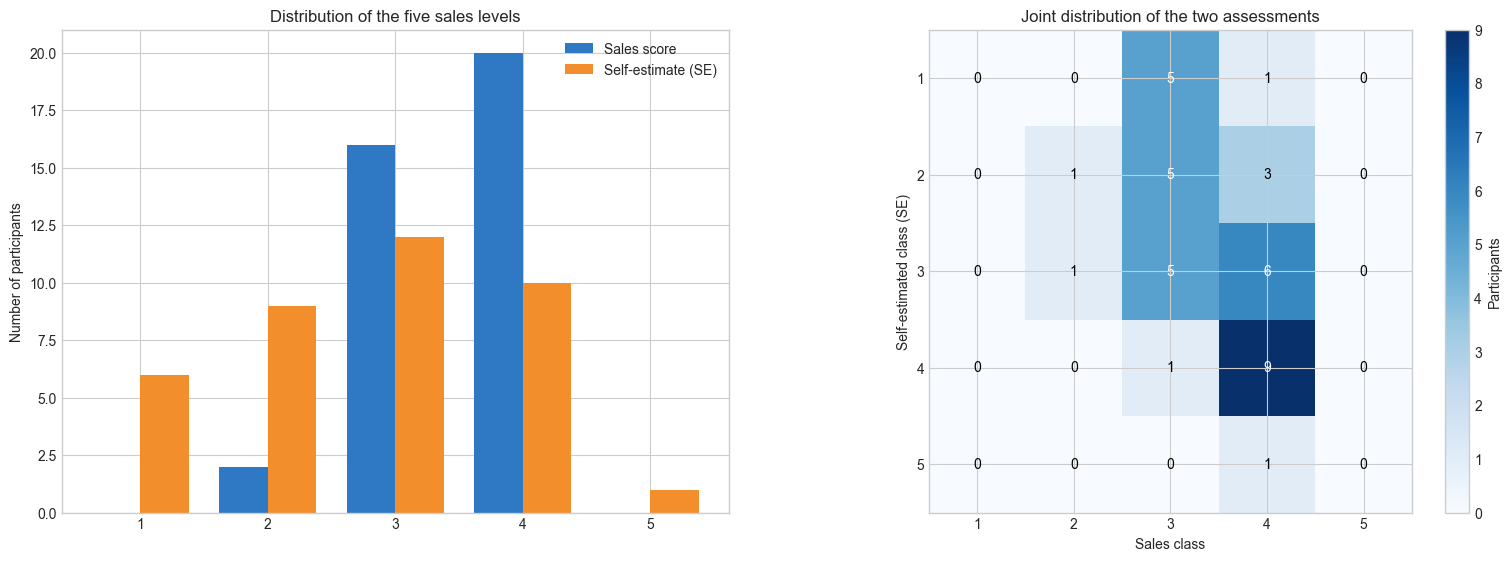

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

participants_df = pd.read_csv('VPTD_Dataset.csv')
personality_traits = [
    'Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness'
]
participant_ids = set(participants_df['Id_name'])

trait_scoring_rules = {
    'Extraversion': {
        'bins': [0, .28, .35, .40, .44, .48, .51, .56, .60, .67, np.inf],
        'scores': list(range(1, 11)),
    },
    'Openness': {
        'bins': [0, .38, .44, .49, .53, .57, .60, .64, .69, .75, np.inf],
        'scores': list(range(1, 11)),
    },
    'Conscientiousness': {
        'bins': [0, .32, .39, .44, .48, .52, .56, .60, .65, .72, np.inf],
        'scores': list(range(1, 11)),
    },
    'Agreeableness': {
        'bins': [0, .28, .34, .38, .42, .45, .49, .52, .57, .63, np.inf],
        'scores': list(range(10, 0, -1)),
    },
    'Neuroticism': {
        'bins': [0, .28, .35, .40, .44, .48, .52, .56, .61, .68, np.inf],
        'scores': list(range(10, 0, -1)),
    },
}

trait_score_columns = []
for trait, rule in trait_scoring_rules.items():
    score_column = f'{trait}_score'
    participants_df[score_column] = pd.cut(
        participants_df[trait],
        bins=rule['bins'],
        labels=rule['scores'],
        right=False,
        include_lowest=True,
    ).astype(int)
    trait_score_columns.append(score_column)

participants_df['SalesScore'] = participants_df[trait_score_columns].mean(axis=1)
participants_df['SalesClass'] = np.ceil(
    participants_df['SalesScore'] / 2
).clip(1, 5).astype(int)

sales_classification_results = participants_df[
    ['Id_name', *personality_traits, 'SalesScore', 'SalesClass', 'SE']
].sort_values(['SalesClass', 'SalesScore'], ascending=False)

display(sales_classification_results.reset_index(drop=True).style.format({
    **{trait: '{:.3f}' for trait in personality_traits},
    'SalesScore': '{:.2f}'
}).background_gradient(subset=['SalesScore'], cmap='YlGn'))

sales_figure, sales_axes = plt.subplots(
    1, 2, figsize=(15, 5.5), constrained_layout=True
)
sales_levels = np.arange(1, 6)
sales_positions = np.arange(5)

calculated_sales_counts = participants_df['SalesClass'].value_counts().reindex(
    sales_levels, fill_value=0
)
self_estimated_sales_counts = participants_df['SE'].value_counts().reindex(
    sales_levels, fill_value=0
)
sales_bar_width = 0.38
sales_axes[0].bar(
    sales_positions - sales_bar_width / 2, calculated_sales_counts, sales_bar_width,
    label='Sales score', color='#2F78C4'
)
sales_axes[0].bar(
    sales_positions + sales_bar_width / 2, self_estimated_sales_counts, sales_bar_width,
    label='Self-estimate (SE)', color='#F28E2B'
)
sales_axes[0].set_xticks(sales_positions, sales_levels)
sales_axes[0].set_ylabel('Number of participants')
sales_axes[0].set_title('Distribution of the five sales levels')
sales_axes[0].legend()

sales_comparison_table = pd.crosstab(
    participants_df['SE'], participants_df['SalesClass']
).reindex(index=sales_levels, columns=sales_levels, fill_value=0)

sales_heatmap = sales_axes[1].imshow(sales_comparison_table, cmap='Blues', vmin=0)
for row in range(5):
    for column in range(5):
        value = sales_comparison_table.iloc[row, column]
        sales_axes[1].text(
            column, row, value, ha='center', va='center',
            color='white' if value > sales_comparison_table.to_numpy().max() / 2 else 'black'
        )

sales_axes[1].set_xticks(sales_positions, sales_levels)
sales_axes[1].set_yticks(sales_positions, sales_levels)
sales_axes[1].set_xlabel('Sales class')
sales_axes[1].set_ylabel('Self-estimated class (SE)')
sales_axes[1].set_title('Joint distribution of the two assessments')
sales_figure.colorbar(sales_heatmap, ax=sales_axes[1], label='Participants')

plt.show()


## Task 2: (5 marks)
* Show the correlation between smiles and Extraversion.
* Show the correlation between head movements and personality traits.

Smile correlations (FWS and R_FWS):


,Feature,Target,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
0,FWS,Extraversion,0.215,0.1940,0.383,0.0175
1,FWS,Agreeableness,-0.229,0.1661,0.079,0.6385
2,FWS,Conscientiousness,-0.165,0.3220,-0.063,0.7070
3,FWS,Neuroticism,0.022,0.8968,0.025,0.8814
4,FWS,Openness,-0.013,0.9389,0.150,0.3693
5,FWS,SE,0.272,0.0982,0.393,0.0148
6,R_FWS,Extraversion,0.134,0.4228,0.353,0.0299
7,R_FWS,Agreeableness,-0.189,0.2562,0.053,0.7535
8,R_FWS,Conscientiousness,-0.153,0.3587,-0.076,0.6483
9,R_FWS,Neuroticism,0.083,0.6215,0.060,0.7198


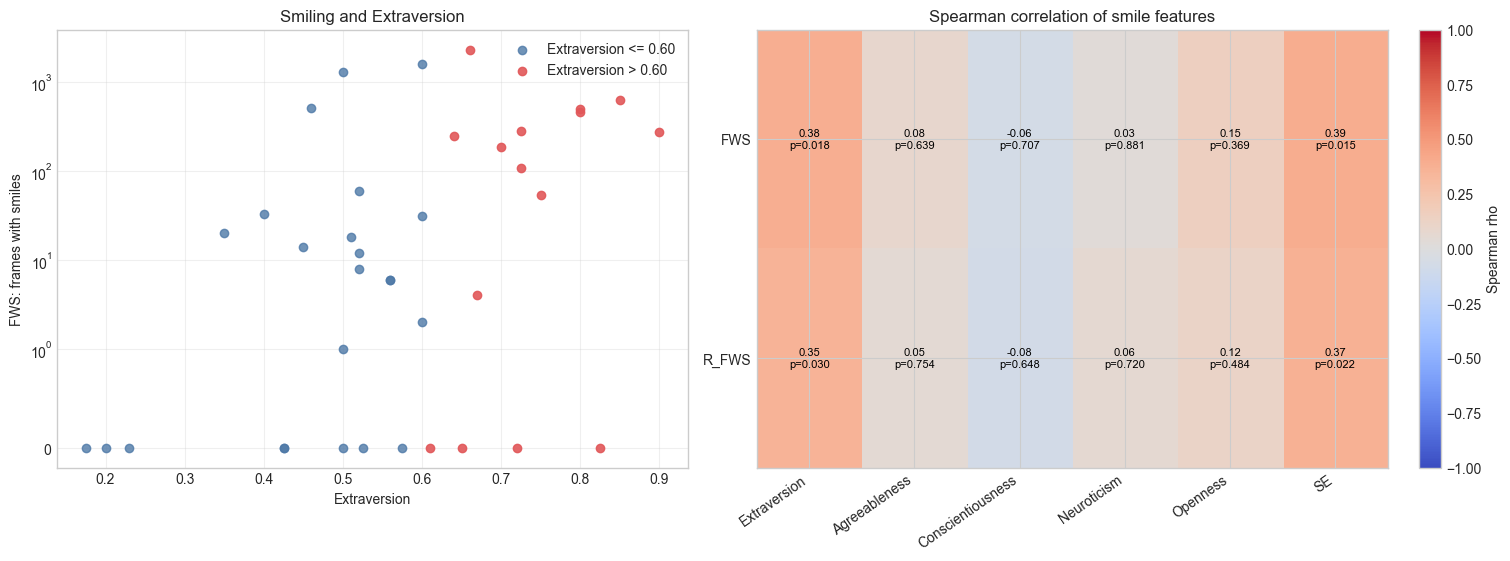

Strongest head-movement relationships:


,Feature,Target,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
67,Yaw_max,Agreeableness,0.484,0.0021,0.480,0.0023
93,Roll_events,Neuroticism,-0.352,0.0301,-0.426,0.0077
95,Roll_events,SE,0.382,0.0178,0.393,0.0147
126,Roll_Pitch_Yaw_events,Extraversion,0.231,0.1623,0.352,0.0300
73,Yaw_range,Agreeableness,0.368,0.0229,0.336,0.0391
90,Roll_events,Extraversion,0.323,0.0480,0.333,0.0411
96,Pitch_events,Extraversion,0.230,0.1652,0.304,0.0632
108,Roll_Pitch_events,Extraversion,0.249,0.1322,0.304,0.0636
42,Pitch_range,Extraversion,0.271,0.1000,0.279,0.0899
23,Roll_mean,SE,0.284,0.0840,0.275,0.0952


Significant event relationships (p < 0.05):


,Feature,Target,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
93,Roll_events,Neuroticism,-0.352,0.0301,-0.426,0.0077
95,Roll_events,SE,0.382,0.0178,0.393,0.0147
126,Roll_Pitch_Yaw_events,Extraversion,0.231,0.1623,0.352,0.0300
90,Roll_events,Extraversion,0.323,0.0480,0.333,0.0411


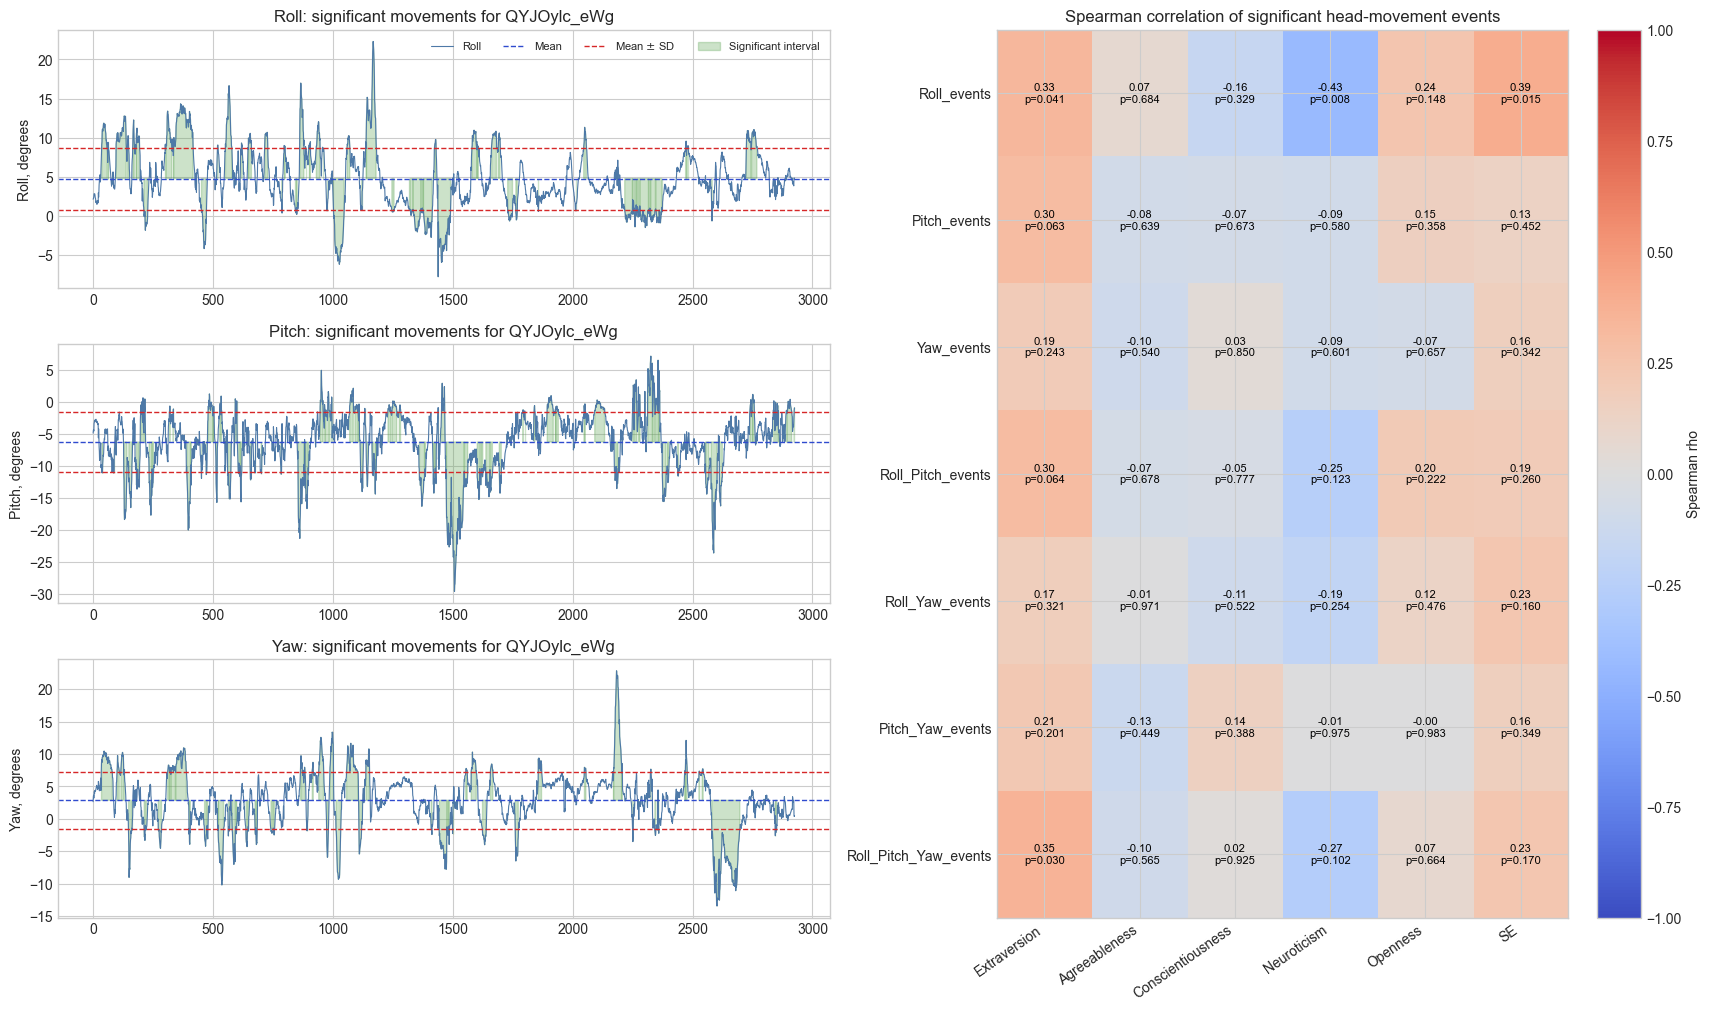

In [27]:
import json
from scipy.stats import pearsonr, spearmanr

smiles_df = pd.read_csv('smiles.csv')
with open('head_movements.json', encoding='utf-8') as file:
    head_movements = json.load(file)

correlation_targets = [*personality_traits, 'SE']

smiles_df['Id_name'] = smiles_df['names'].str.replace('.mp4', '', regex=False)
smiles_df['FWS'] = smiles_df['smiles']
smiles_df['R_FWS'] = smiles_df['smiles'] / smiles_df['total_frames']

nonverbal_data = participants_df.merge(
    smiles_df[['Id_name', 'FWS', 'R_FWS', 'total_frames']],
    on='Id_name', how='inner', validate='one_to_one'
)

def correlation_table(frame, feature_columns, target_columns):
    rows = []
    for feature in feature_columns:
        for target in target_columns:
            pair = frame[[feature, target]].dropna()
            if pair[feature].nunique() < 2 or pair[target].nunique() < 2:
                continue
            pearson_r, pearson_p = pearsonr(pair[feature], pair[target])
            spearman_r, spearman_p = spearmanr(pair[feature], pair[target])
            rows.append({
                'Feature': feature,
                'Target': target,
                'Pearson_r': pearson_r,
                'Pearson_p': pearson_p,
                'Spearman_rho': spearman_r,
                'Spearman_p': spearman_p,
            })
    return pd.DataFrame(rows)

def annotated_heatmap(ax, correlations, feature_order, target_order, title):
    rho = correlations.pivot(index='Feature', columns='Target', values='Spearman_rho')
    p_values = correlations.pivot(index='Feature', columns='Target', values='Spearman_p')
    rho = rho.reindex(index=feature_order, columns=target_order)
    p_values = p_values.reindex(index=feature_order, columns=target_order)

    image = ax.imshow(rho, cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')
    for row in range(len(feature_order)):
        for column in range(len(target_order)):
            value = rho.iloc[row, column]
            p_value = p_values.iloc[row, column]
            ax.text(column, row, f'{value:.2f}\np={p_value:.3f}',
                    ha='center', va='center', fontsize=8,
                    color='white' if abs(value) >= .55 else 'black')
    ax.set_xticks(range(len(target_order)), target_order, rotation=35, ha='right')
    ax.set_yticks(range(len(feature_order)), feature_order)
    ax.set_title(title)
    return image

smile_features = ['FWS', 'R_FWS']
smile_correlations = correlation_table(nonverbal_data, smile_features, correlation_targets)

print('Smile correlations (FWS and R_FWS):')
display(smile_correlations.style.format({
    'Pearson_r': '{:.3f}', 'Pearson_p': '{:.4f}',
    'Spearman_rho': '{:.3f}', 'Spearman_p': '{:.4f}'
}).background_gradient(subset=['Spearman_rho'], cmap='coolwarm', vmin=-1, vmax=1))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)

high_extraversion = nonverbal_data['Extraversion'] > 0.60
axes[0].scatter(nonverbal_data.loc[~high_extraversion, 'Extraversion'],
                nonverbal_data.loc[~high_extraversion, 'FWS'],
                color='#4E79A7', alpha=0.8, label='Extraversion <= 0.60')
axes[0].scatter(nonverbal_data.loc[high_extraversion, 'Extraversion'],
                nonverbal_data.loc[high_extraversion, 'FWS'],
                color='#E15759', alpha=0.9, label='Extraversion > 0.60')
axes[0].set_yscale('symlog', linthresh=1)
axes[0].set_xlabel('Extraversion')
axes[0].set_ylabel('FWS: frames with smiles')
axes[0].set_title('Smiling and Extraversion')
axes[0].legend()
axes[0].grid(True, which='both', alpha=0.3)

smile_image = annotated_heatmap(
    axes[1], smile_correlations, smile_features, correlation_targets,
    'Spearman correlation of smile features'
)
fig.colorbar(smile_image, ax=axes[1], label='Spearman rho')
plt.show()

axes_names = ['Roll', 'Pitch', 'Yaw']
compound_axes = {
    'Roll': ('Roll',),
    'Pitch': ('Pitch',),
    'Yaw': ('Yaw',),
    'Roll_Pitch': ('Roll', 'Pitch'),
    'Roll_Yaw': ('Roll', 'Yaw'),
    'Pitch_Yaw': ('Pitch', 'Yaw'),
    'Roll_Pitch_Yaw': ('Roll', 'Pitch', 'Yaw'),
}

def count_true_intervals(mask):
    mask = np.asarray(mask, dtype=bool)
    if mask.size == 0:
        return 0
    return int(mask[0]) + int(np.count_nonzero(mask[1:] & ~mask[:-1]))

def significant_event_count(values, sd_multiplier=1.0):
    values = np.asarray(values, dtype=float)
    threshold = sd_multiplier * values.std(ddof=0)
    significant = np.abs(values - values.mean()) > threshold
    return count_true_intervals(significant)

head_rows = []
for participant, participant_signals in head_movements.items():
    frame_count = min(len(participant_signals[axis]) for axis in axes_names)
    signals = {
        axis: np.asarray(participant_signals[axis][:frame_count], dtype=float)
        for axis in axes_names
    }
    row = {'Id_name': participant, 'Head_frames': frame_count}

    for axis, values in signals.items():
        row.update({
            f'{axis}_min': values.min(),
            f'{axis}_max': values.max(),
            f'{axis}_range': np.ptp(values),
            f'{axis}_mean': values.mean(),
            f'{axis}_std': values.std(ddof=0),
        })

    for feature_name, feature_axes in compound_axes.items():
        compound_signal = np.prod([signals[axis] for axis in feature_axes], axis=0)
        row[f'{feature_name}_events'] = significant_event_count(compound_signal)

    head_rows.append(row)

head_features = pd.DataFrame(head_rows)
head_data = participants_df.merge(head_features, on='Id_name', validate='one_to_one')

event_features = [f'{name}_events' for name in compound_axes]
basic_features = [
    column for column in head_features.columns
    if column not in {'Id_name', 'Head_frames', *event_features}
]
head_correlations = correlation_table(
    head_data, basic_features + event_features, correlation_targets
)

strongest_head_relations = (
    head_correlations.assign(abs_spearman=lambda table: table['Spearman_rho'].abs())
    .sort_values(['abs_spearman'], ascending=[False])
    .drop(columns='abs_spearman')
    .head(20)
)
print('Strongest head-movement relationships:')
display(strongest_head_relations.style.format({
    'Pearson_r': '{:.3f}', 'Pearson_p': '{:.4f}',
    'Spearman_rho': '{:.3f}', 'Spearman_p': '{:.4f}'
}).background_gradient(subset=['Spearman_rho'], cmap='coolwarm', vmin=-1, vmax=1))

event_correlations = head_correlations[head_correlations['Feature'].isin(event_features)]
significant_events = event_correlations[event_correlations['Spearman_p'] < 0.05]
print('Significant event relationships (p < 0.05):')
display(significant_events.sort_values('Spearman_p').style.format({
    'Pearson_r': '{:.3f}', 'Pearson_p': '{:.4f}',
    'Spearman_rho': '{:.3f}', 'Spearman_p': '{:.4f}'
}))

lengths = {participant: len(values['Roll']) for participant, values in head_movements.items()}
median_length = np.median(list(lengths.values()))
example_id = min(lengths, key=lambda participant: abs(lengths[participant] - median_length))

fig = plt.figure(figsize=(17, 10), constrained_layout=True)
grid = fig.add_gridspec(3, 2, width_ratios=[1.35, 1])

for index, axis_name in enumerate(axes_names):
    ax = fig.add_subplot(grid[index, 0])
    values = np.asarray(head_movements[example_id][axis_name], dtype=float)
    center = values.mean()
    standard_deviation = values.std(ddof=0)
    significant = np.abs(values - center) > standard_deviation
    frames = np.arange(len(values))

    ax.plot(frames, values, color='#4E79A7', linewidth=.8, label=axis_name)
    ax.axhline(center, color='#2F4BCE', linestyle='--', linewidth=1, label='Mean')
    ax.axhline(center + standard_deviation, color='#D62728', linestyle='--', linewidth=1,
               label=r'Mean $\pm$ SD')
    ax.axhline(center - standard_deviation, color='#D62728', linestyle='--', linewidth=1)
    ax.fill_between(frames, values, center, where=significant,
                    color='#59A14F', alpha=.30, label='Significant interval')
    ax.set_ylabel(f'{axis_name}, degrees')
    ax.set_title(f'{axis_name}: significant movements for {example_id}')
    if index == 0:
        ax.legend(loc='upper right', ncol=4, fontsize=8)

heatmap_axis = fig.add_subplot(grid[:, 1])
head_image = annotated_heatmap(
    heatmap_axis, event_correlations, event_features, correlation_targets,
    'Spearman correlation of significant head-movement events'
)
fig.colorbar(head_image, ax=heatmap_axis, label='Spearman rho')
plt.show()


## Task 3: (5 marks)
Prove the correlation you found between non-verbal cues (smiles and head movements) with personality traits, by training some models to predict the correlated traits depending on the extracted features.

Train size: 26 test size: 12


,Target,Feature,Model,CV_RMSE,MAE,MSE,RMSE,Best_parameters
0,Extraversion,FWS,Random forest,0.1411,0.1515,0.0336,0.1834,"{'max_depth': 4, 'min_samples_leaf': 4, 'n_estimators': 300}"
1,Extraversion,FWS,MLP,0.1497,0.1453,0.0310,0.1761,"{'mlpregressor__activation': 'relu', 'mlpregressor__alpha': 0.1, 'mlpregressor__hidden_layer_sizes': (2,)}"
2,Extraversion,FWS,Polynomial regression,0.1597,0.1617,0.0359,0.1894,"{'polynomialfeatures__degree': 1, 'ridge__alpha': 10.0}"
3,Extraversion,FWS,Mean baseline,0.1611,0.1617,0.0368,0.1918,{}
4,Extraversion,R_FWS,Random forest,0.1372,0.1721,0.0421,0.2051,"{'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 300}"
5,Extraversion,R_FWS,MLP,0.1389,0.1608,0.0379,0.1947,"{'mlpregressor__activation': 'relu', 'mlpregressor__alpha': 0.01, 'mlpregressor__hidden_layer_sizes': (8,)}"
6,Extraversion,R_FWS,Polynomial regression,0.1414,0.1500,0.0322,0.1795,"{'polynomialfeatures__degree': 3, 'ridge__alpha': 0.1}"
7,Extraversion,R_FWS,Mean baseline,0.1611,0.1617,0.0368,0.1918,{}
8,Extraversion,Roll_Pitch_Yaw_events,Random forest,0.1567,0.1289,0.0353,0.1878,"{'max_depth': 4, 'min_samples_leaf': 4, 'n_estimators': 300}"
9,Extraversion,Roll_Pitch_Yaw_events,Polynomial regression,0.1593,0.1528,0.0348,0.1865,"{'polynomialfeatures__degree': 1, 'ridge__alpha': 10.0}"


Model selected by training cross-validation for each relationship:


,Target,Feature,Model,CV_RMSE,MAE,MSE,RMSE,Best_parameters
0,Extraversion,FWS,Random forest,0.1411,0.1515,0.0336,0.1834,"{'max_depth': 4, 'min_samples_leaf': 4, 'n_estimators': 300}"
4,Extraversion,R_FWS,Random forest,0.1372,0.1721,0.0421,0.2051,"{'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 300}"
8,Extraversion,Roll_Pitch_Yaw_events,Random forest,0.1567,0.1289,0.0353,0.1878,"{'max_depth': 4, 'min_samples_leaf': 4, 'n_estimators': 300}"
12,Extraversion,Roll_events,Polynomial regression,0.1560,0.1549,0.0352,0.1876,"{'polynomialfeatures__degree': 3, 'ridge__alpha': 100.0}"
16,Neuroticism,Roll_events,MLP,0.1643,0.1487,0.0331,0.1820,"{'mlpregressor__activation': 'relu', 'mlpregressor__alpha': 0.1, 'mlpregressor__hidden_layer_sizes': (8,)}"


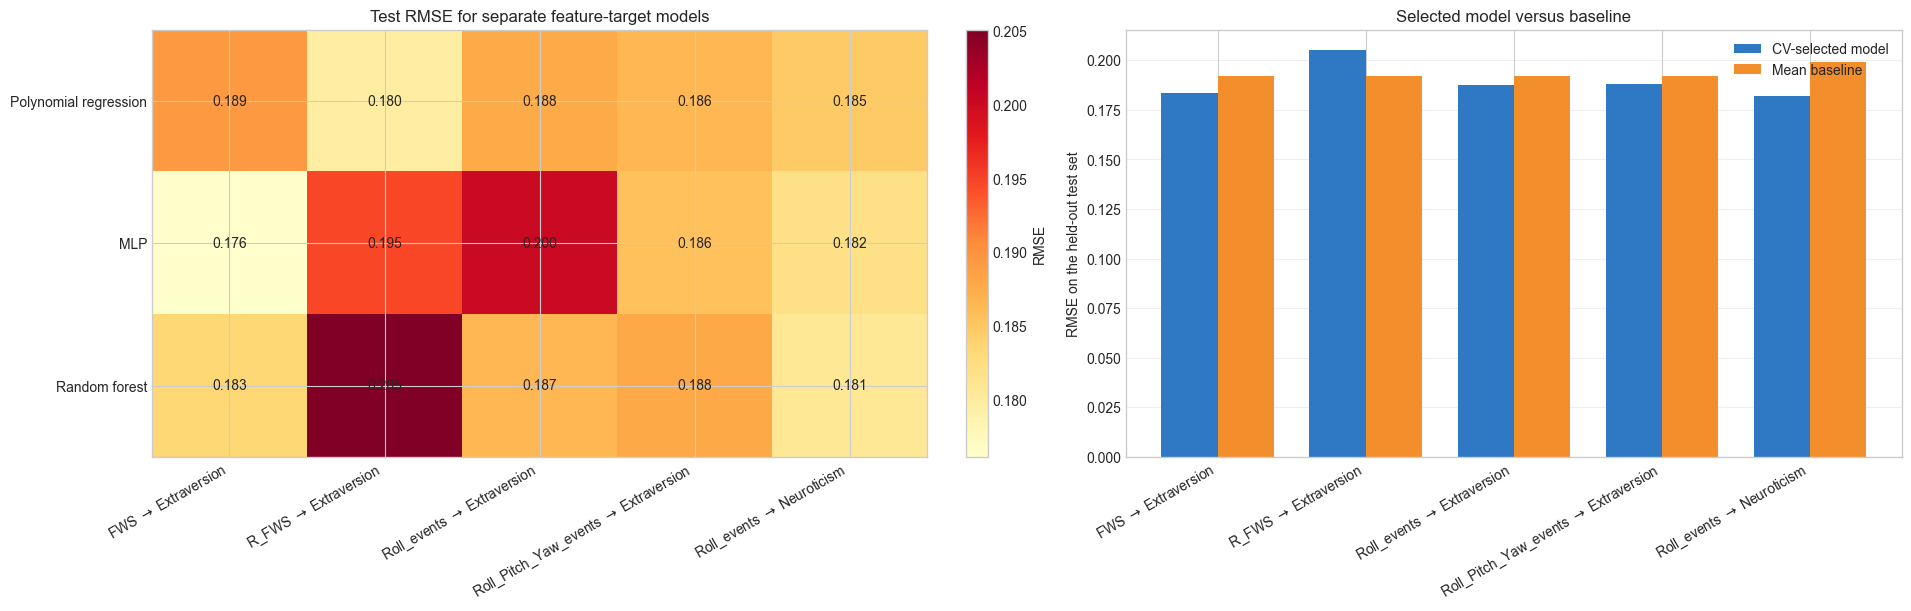

In [31]:
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

modeling_data = nonverbal_data.merge(
    head_features, on='Id_name', how='inner', validate='one_to_one'
)

prediction_feature_sets = {
    'Extraversion': [
        'FWS', 'R_FWS', 'Roll_events', 'Roll_Pitch_Yaw_events'
    ],
    'Neuroticism': ['Roll_events'],
}

train_index, test_index = train_test_split(
    modeling_data.index, test_size=0.30, random_state=42
)
inner_cv = KFold(n_splits=5, shuffle=True, random_state=42)

regression_search_spaces = {
    'Polynomial regression': {
        'estimator': make_pipeline(
            StandardScaler(),
            PolynomialFeatures(include_bias=False),
            Ridge(),
        ),
        'parameters': {
            'polynomialfeatures__degree': [1, 2, 3],
            'ridge__alpha': [0.01, 0.1, 1.0, 10.0, 100.0],
        },
    },
    'MLP': {
        'estimator': make_pipeline(
            StandardScaler(),
            MLPRegressor(solver='lbfgs', max_iter=5000, random_state=42),
        ),
        'parameters': {
            'mlpregressor__hidden_layer_sizes': [(2,), (4,), (8,)],
            'mlpregressor__activation': ['tanh', 'relu'],
            'mlpregressor__alpha': [0.01, 0.1, 1.0, 10.0],
        },
    },
    'Random forest': {
        'estimator': RandomForestRegressor(random_state=42),
        'parameters': {
            'n_estimators': [100, 300],
            'max_depth': [2, 4, None],
            'min_samples_leaf': [1, 2, 4],
        },
    },
}

def regression_metrics(actual, predicted):
    mse = mean_squared_error(actual, predicted)
    return {
        'MAE': mean_absolute_error(actual, predicted),
        'MSE': mse,
        'RMSE': np.sqrt(mse),
    }

def tune_and_evaluate_regressors(frame, feature_sets, search_spaces, train_rows, test_rows, cv):
    score_rows = []
    predictions = {}
    fitted_regressors = {}

    for target, feature_columns in feature_sets.items():
        y_train = frame.loc[train_rows, target]
        y_test = frame.loc[test_rows, target]

        for feature in feature_columns:
            x_train = frame.loc[train_rows, [feature]]
            x_test = frame.loc[test_rows, [feature]]

            for model_name, search_space in search_spaces.items():
                search = GridSearchCV(
                    estimator=clone(search_space['estimator']),
                    param_grid=search_space['parameters'],
                    scoring='neg_root_mean_squared_error',
                    cv=cv,
                    n_jobs=1,
                )
                search.fit(x_train, y_train)
                predicted = search.predict(x_test)

                score_rows.append({
                    'Target': target,
                    'Feature': feature,
                    'Model': model_name,
                    'CV_RMSE': -search.best_score_,
                    **regression_metrics(y_test, predicted),
                    'Best_parameters': search.best_params_,
                })
                predictions[(target, feature, model_name)] = pd.DataFrame({
                    'Id_name': frame.loc[test_rows, 'Id_name'].to_numpy(),
                    'Actual': y_test.to_numpy(),
                    'Predicted': predicted,
                })
                fitted_regressors[(target, feature, model_name)] = search.best_estimator_

            baseline = DummyRegressor(strategy='mean')
            baseline_cv_rmse = -cross_val_score(
                baseline,
                x_train,
                y_train,
                scoring='neg_root_mean_squared_error',
                cv=cv,
                n_jobs=1,
            ).mean()
            baseline.fit(x_train, y_train)
            baseline_prediction = baseline.predict(x_test)
            score_rows.append({
                'Target': target,
                'Feature': feature,
                'Model': 'Mean baseline',
                'CV_RMSE': baseline_cv_rmse,
                **regression_metrics(y_test, baseline_prediction),
                'Best_parameters': {},
            })
            predictions[(target, feature, 'Mean baseline')] = pd.DataFrame({
                'Id_name': frame.loc[test_rows, 'Id_name'].to_numpy(),
                'Actual': y_test.to_numpy(),
                'Predicted': baseline_prediction,
            })

    return pd.DataFrame(score_rows), predictions, fitted_regressors

regression_results, regression_predictions, fitted_regressors = tune_and_evaluate_regressors(
    modeling_data,
    prediction_feature_sets,
    regression_search_spaces,
    train_index,
    test_index,
    inner_cv,
)

regression_results = regression_results.sort_values(
    ['Target', 'Feature', 'CV_RMSE', 'RMSE'], ignore_index=True
)

print(
    f'Train size: {len(train_index)} '
    f'test size: {len(test_index)}'
)
display(regression_results.style.format({
    'CV_RMSE': '{:.4f}', 'MAE': '{:.4f}', 'MSE': '{:.4f}', 'RMSE': '{:.4f}'
}).background_gradient(subset=['CV_RMSE', 'RMSE'], cmap='YlOrRd_r'))

trained_model_results = regression_results[
    regression_results['Model'] != 'Mean baseline'
]
best_regressors = trained_model_results.loc[
    trained_model_results.groupby(['Target', 'Feature'])['CV_RMSE'].idxmin()
].sort_values(['Target', 'Feature'])

print('Model selected by training cross-validation for each relationship:')
display(best_regressors.style.format({
    'CV_RMSE': '{:.4f}', 'MAE': '{:.4f}', 'MSE': '{:.4f}', 'RMSE': '{:.4f}'
}))

pair_order = [
    (target, feature)
    for target, features in prediction_feature_sets.items()
    for feature in features
]
pair_labels = [rf'{feature} $\to$ {target}' for target, feature in pair_order]
model_order = list(regression_search_spaces)

rmse_comparison = regression_results.pivot_table(
    index='Model', columns=['Target', 'Feature'], values='RMSE'
).reindex(index=model_order, columns=pd.MultiIndex.from_tuples(pair_order))

baseline_rmse = (
    regression_results[regression_results['Model'] == 'Mean baseline']
    .set_index(['Target', 'Feature'])['RMSE']
    .reindex(pair_order)
)
selected_test_rmse = (
    best_regressors.set_index(['Target', 'Feature'])['RMSE']
    .reindex(pair_order)
)

regression_figure, regression_axes = plt.subplots(
    1, 2, figsize=(19, 6), constrained_layout=True
)

rmse_image = regression_axes[0].imshow(
    rmse_comparison, cmap='YlOrRd', aspect='auto'
)
for row in range(len(model_order)):
    for column in range(len(pair_order)):
        value = rmse_comparison.iloc[row, column]
        regression_axes[0].text(
            column, row, f'{value:.3f}', ha='center', va='center'
        )
regression_axes[0].set_xticks(
    range(len(pair_labels)), pair_labels, rotation=30, ha='right'
)
regression_axes[0].set_yticks(range(len(model_order)), model_order)
regression_axes[0].set_title('Test RMSE for separate feature-target models')
regression_figure.colorbar(rmse_image, ax=regression_axes[0], label='RMSE')

pair_positions = np.arange(len(pair_order))
bar_width = 0.38
regression_axes[1].bar(
    pair_positions - bar_width / 2,
    selected_test_rmse,
    bar_width,
    label='CV-selected model',
    color='#2F78C4',
)
regression_axes[1].bar(
    pair_positions + bar_width / 2,
    baseline_rmse,
    bar_width,
    label='Mean baseline',
    color='#F28E2B',
)
regression_axes[1].set_xticks(
    pair_positions, pair_labels, rotation=30, ha='right'
)
regression_axes[1].set_ylabel('RMSE on the held-out test set')
regression_axes[1].set_title('Selected model versus baseline')
regression_axes[1].legend()
regression_axes[1].grid(axis='y', alpha=0.3)

plt.show()

#List of Papers:


1.   http://dx.doi.org/10.23919/FRUCT58615.2023.10143053
2.   http://dx.doi.org/10.3390/data8070113
3.   http://dx.doi.org/10.23919/FRUCT61870.2024.10516365

